# bind_tools와 병렬 호출

**이 노트북에서 할 일**

1. 주문 둘을 묻는 질문에, 모델이 한 응답에 도구 호출 요청을 몇 건 보내는지 봅니다.
2. 도구 호출 요청을 프로그램이 차례로 실행해 도구 메시지를 만들고, 호출 ID로 짝을 맞춥니다.
3. 도구 메시지를 모델에게 보내 최종 답을 받고, 두 금액이 들어 있는지 셉니다.
4. 한 응답에 하나씩만 담게 바꿔, 모델 요청 수와 토큰을 견줍니다.

**준비물** — 프로젝트 폴더의 `.env` 파일에 `OPENAI_API_KEY`가 있어야 합니다.
모델은 `gpt-5.4-mini`이고, 모델 요청은 모두 5번입니다.
3절과 5절에서 1번씩, 6절에서 3번을 보냅니다.
요금표로 센 예상 비용은 모두 합쳐 0.01달러 아래이고, 청구 금액이 아닙니다.

도구는 주문 한 건을 찾는 도구 하나이고, 실습 폴더의 주문 CSV를 읽기만 합니다.
새로 쓰는 파일은 없습니다.
03·04절 함수와 Ch 6 06절 함수는 도구 파일 `order_tools.py`에서 가져옵니다.
교재 출력을 만든 실행에서는 노트북 전체가 10초 안에 끝났습니다.
모델 응답을 기다리는 시간은 네트워크와 실행 때에 따라 달라집니다.

**기준 버전** — 첫 셀에서 패키지 다섯을 설치합니다.
판은 langchain 1.4.0, langchain-core 1.6.2, langchain-openai 1.6.0입니다.
pandas 3.0.5와 python-dotenv 1.2.3도 함께 설치합니다.
교재 출력은 Linux의 Python 3.12.13으로 만들었습니다.
다른 판과 Windows·macOS에서는 이번에 실행하지 않았습니다.

**강의와 실습 범위** — 강의 시간에는 2~5절을 읽습니다.
도구 호출 요청 둘을 실행하고, 도구 메시지를 보내 최종 답을 받는 자리입니다.
6~7절은 여럿 담기를 끄고 두 흐름의 요청 수와 예상 비용을 견주는 자리입니다.
이 부분은 실습 시간에 실행합니다.

실습 폴더 `labs/part5/ch19-model-tools`에서 `uv sync --locked`를 실행합니다.
그다음 `notebooks/` 폴더의 이 노트북을 열고, 실습 폴더의 `.venv` 커널을 고릅니다.
첫 셀부터 순서대로 실행합니다.

## 오늘 볼 그림

![세로선 셋이 있는 차례 그림으로 왼쪽부터 노트북 코드, gpt-5.4-mini, 도구 get_order_by_id입니다. 노트북 코드가 모델에 요청 1 질문과 명세 여럿 담기 True를 보내고, 모델이 도구 호출 요청 둘 O101 O103을 적어 보냅니다. 노트북 코드가 도구에 첫 요청 O101을 실행해 도구 메시지 금액 32000을 받고, 둘째 요청 O103을 실행해 도구 메시지 금액 27000을 받습니다. 노란 메모 호출 ID 짝이 맞음 True 뒤에 노트북 코드가 모델에 요청 2 질문 첫 응답 도구 메시지 둘을 보내고, 모델이 최종 답 도구 호출 요청 0건을 보내며, 마지막 노란 메모에 답 글에 32000 27000 있음이 적힌 그림](attachment:05-1-요청-둘을-실행하고-함께-보내기.png)

위에서 아래로 읽고, 세로선은 왼쪽부터 노트북 코드, 모델, 도구입니다.
요청 1의 응답에 도구 호출 요청 둘이 함께 옵니다.
노트북 코드가 두 요청을 차례로 도구에 넣어 도구 메시지 둘을 받습니다.
요청 2에 도구 메시지 둘을 함께 싣자, 모델이 도구 호출 요청 없이 최종 답을 적습니다.
노란 메모는 노트북 4·5절 출력입니다.
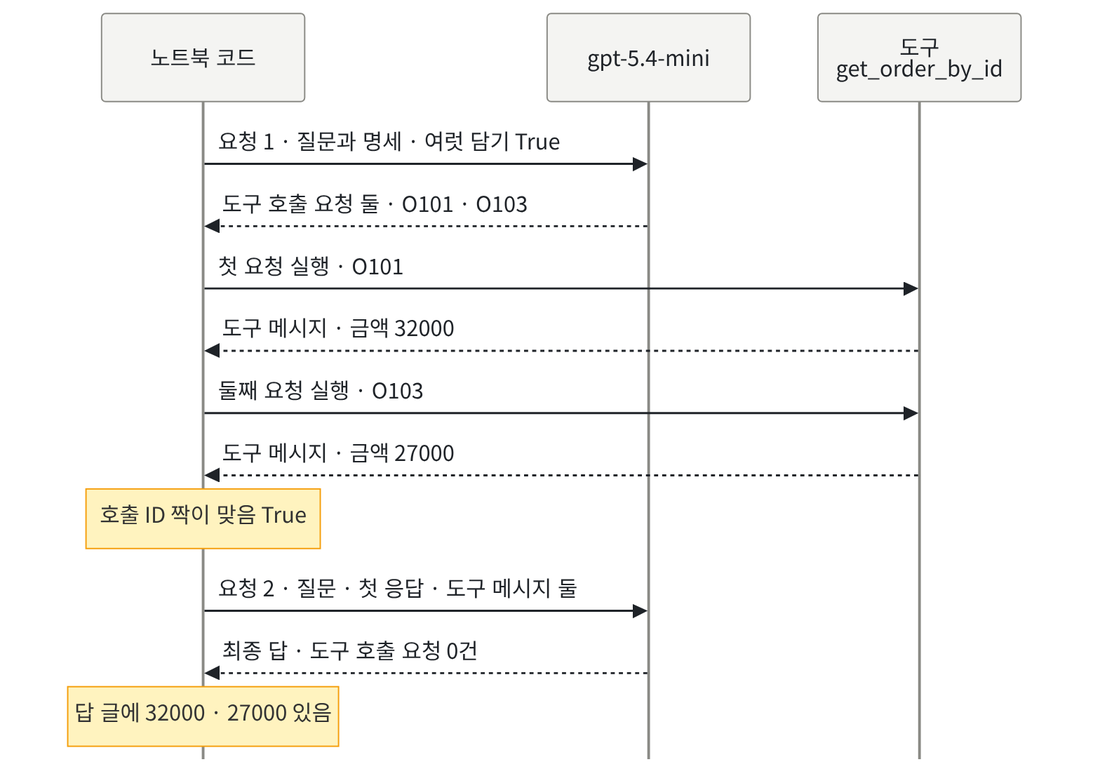

## 1. 준비

04절은 모델이 적어 보낸 도구 호출 요청을 읽기만 하고, 도구는 실행하지 않았습니다.
이 절은 그 요청을 프로그램이 받아 도구를 실행하고, 결과를 모델에게 다시 보냅니다.
제목의 「병렬 호출」은 한 응답 안에 도구 호출 요청이 여럿 오는 것을 뜻합니다.

첫 셀은 패키지 다섯 개를 설치하고 설치된 판 번호를 출력합니다.
설치에는 몇십 초가 걸릴 수 있습니다.

In [1]:
# 이 절에서 쓰는 패키지를 설치하고 버전을 확인합니다
%pip install -q "langchain==1.4.0" "langchain-core==1.6.2" "langchain-openai==1.6.0" "pandas==3.0.5" "python-dotenv==1.2.3"
from importlib.metadata import version

print("langchain:", version("langchain"))
print("langchain-core:", version("langchain-core"))
print("langchain-openai:", version("langchain-openai"))
print("pandas:", version("pandas"))
print("python-dotenv:", version("python-dotenv"))

Note: you may need to restart the kernel to use updated packages.
langchain: 1.4.0
langchain-core: 1.6.2
langchain-openai: 1.6.0
pandas: 3.0.5
python-dotenv: 1.2.3


**결과 읽기** — 출력 줄 `langchain: 1.4.0`·`langchain-core: 1.6.2`·`langchain-openai: 1.6.0`이 보입니다.
출력 줄 `pandas: 3.0.5`와 `python-dotenv: 1.2.3`도 잠금과 같은 판입니다.
이 노트북의 출력은 2026-09-24에 이 판으로 실행한 결과입니다.

앞에서 배운 함수는 `order_tools.py`에 모아 두었습니다. 파일을 열면 코드를 볼 수 있습니다. 노트북과 같은 폴더(`notebooks/`)에 있는 파일입니다. 커널이 `notebooks/` 폴더에서 시작해야 이 파일을 가져올 수 있습니다.

다음 셀은 이 절에서 쓸 이름을 가져옵니다.
메시지 클래스 `HumanMessage`는 Ch 13 04절에서 질문 메시지를 만들 때 썼습니다.
도구 파일에서는 03절 몸통 함수 `find_order`와 04절 함수 `tool_call_names`를 가져옵니다.
Ch 6 06절 함수 `estimate_cost`는 04절에서 도구 파일에 옮긴 판입니다.

In [2]:
# 모델·도구·메시지를 만드는 이름과 도구 파일의 함수 셋을 가져옵니다
import json
import os

from langchain.chat_models import init_chat_model
from langchain.tools import tool
from langchain_core.messages import HumanMessage

from order_tools import estimate_cost, find_order, tool_call_names

print("가져온 이름:", "json", "os", "init_chat_model", "tool", "HumanMessage")

가져온 이름: json os init_chat_model tool HumanMessage


**결과 읽기** — 출력 줄에 가져온 이름 다섯이 보입니다.
도구 파일에서 가져온 함수 셋은 셀의 `from order_tools import …` 줄에 적혀 있습니다.
모듈 `json`은 Ch 17 03절처럼 JSON 글을 딕셔너리로 바꿀 때 씁니다.

다음 셀은 01~04절과 같은 방법으로 주문 CSV가 있는 프로젝트 맨 위 폴더를 찾습니다.
이 절은 도구를 실행하므로, 도구 몸통이 이 CSV 파일을 읽습니다.

In [3]:
# 노트북을 어느 폴더에서 열어도 주문 CSV를 찾게 후보 세 곳을 차례로 봅니다
candidates = [".", "../../..", "../../../.."]
root_path = None
for candidate in candidates:
    if os.path.exists(candidate + "/labs/part5/ch19-model-tools/data/orders.csv"):
        root_path = candidate
        break
print("찾은 프로젝트 맨 위:", root_path)
assert root_path is not None, "notebooks 폴더나 실습 폴더 맨 위에서 노트북을 열어 주세요."
# CSV 파일 위치는 노트북이 정해 두는 값입니다(모델이 고를 값이 아님)
csv_path = root_path + "/labs/part5/ch19-model-tools/data/orders.csv"

찾은 프로젝트 맨 위: .


**결과 읽기** — 출력 줄 `찾은 프로젝트 맨 위: .`은 교재 출력을 프로젝트 맨 위에서 실행했다는 뜻입니다.
교재 출력은 실행 도구에 도구 파일 폴더를 따로 알려 준 실행이라 `.`이 찍혔습니다.
노트북을 `notebooks/` 폴더에서 열면 이 줄에 `../../../..`가 찍힙니다.
셀 안의 안내 글은 실습 폴더 맨 위도 적었지만, 도구 파일을 가져오려면 `notebooks/` 폴더에서 열어야 합니다.

## 2. 키와 모델 준비

모델은 04절과 같은 `gpt-5.4-mini`이고, 과정의 같은 설정으로 부릅니다.

API 키가 있는지 확인합니다. `True` 값이 나오면 다음으로 넘어갑니다.

In [4]:
# .env 파일에서 OpenAI API 키를 읽습니다(키 값은 출력하지 않습니다)
import os
from dotenv import find_dotenv, load_dotenv

env_path = find_dotenv(usecwd=True)
load_dotenv(env_path)
has_key = os.getenv("OPENAI_API_KEY") is not None
print("OPENAI_API_KEY 설정 여부:", has_key)
assert has_key, "프로젝트 폴더의 .env 파일에 OPENAI_API_KEY를 적어 주세요."

OPENAI_API_KEY 설정 여부: True


실습에 쓸 모델을 준비합니다.
temperature 값을 0으로 두어도, 모델이 보내는 도구 호출 요청이 매번 같다고 보장하지는 않습니다.

In [5]:
# 실습에 쓸 모델을 준비합니다
model = init_chat_model(
    "openai:gpt-5.4-mini",
    temperature=0,
    reasoning_effort="none",
)
print("모델 이름:", model.model_name)
print("temperature:", model.temperature)

모델 이름: gpt-5.4-mini
temperature: 0.0


**결과 읽기** — 모델 이름 `gpt-5.4-mini`, temperature `0.0`이 보이면 준비가 끝났습니다.
이 노트북의 출력은 2026-09-24에 이 모델로 실행한 결과입니다.

## 3. 도구를 알려 주고 질문 하나 보내기

이 절에서 쓰는 도구는 주문 한 건을 찾는 도구 하나입니다.
04절은 설명의 몫만 보려고 공개 이름을 가렸지만, 이 절은 가릴 까닭이 없습니다.
그래서 03절 이름 `get_order_by_id`와 03절 자세한 판 설명을 그대로 씁니다.

다음 셀은 03절 자세한 판 한 건 도구와 같은 정의로 도구를 만듭니다.
몸통은 도구 파일에서 가져온 03절 몸통 함수 `find_order`를 부르는 한 줄입니다.

In [6]:
# 03절 이름과 자세한 판 설명으로 주문 한 건 도구를 만듭니다
@tool
def get_order_by_id(order_id: str):
    """주문 번호로 주문 한 건을 찾습니다. 질문에 O103 같은 주문 번호가 있을 때 씁니다. 인자 order_id는 찾을 주문 번호입니다. 그 주문 한 줄을 딕셔너리로 내놓고, 없으면 None을 내놓습니다."""
    return find_order(csv_path, order_id)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
독스트링은 03절 자세한 판 설명 네 문장과 같은 글입니다.
둘째 문장은 질문에 주문 번호가 있을 때 이 도구를 쓴다고 적습니다.

다음 셀은 이 도구 하나를 목록에 담아, 메서드 `bind_tools`로 모델에게 알려 줍니다.
04절은 인자 `parallel_tool_calls=False`로 한 응답에 도구 호출 요청을 하나까지만 받았습니다.
이번에는 값을 `True`로 두어, 한 응답에 여럿을 담아도 되게 합니다.
이 절에서는 이 인자를 여럿 담기라고 부릅니다.

In [7]:
# 도구 하나를 목록에 담아 모델에게 알려 주고, 요청에 실을 값을 봅니다(요청은 아직 없음)
tools = [get_order_by_id]
# 인자 parallel_tool_calls=True는 한 응답에 도구 호출 요청을 여럿 담아도 되게 합니다
parallel_model = model.bind_tools(tools, parallel_tool_calls=True)
print("실어 보낼 명세 수:", len(parallel_model.kwargs["tools"]))
print("여럿 담기:", parallel_model.kwargs["parallel_tool_calls"])

실어 보낼 명세 수: 1
여럿 담기: True


**결과 읽기** — 출력 줄 `실어 보낼 명세 수: 1`은 도구 하나의 명세가 실린다는 뜻입니다.
출력 줄 `여럿 담기: True`처럼, 인자 값도 요청마다 함께 실립니다.
인자를 아예 빼면 요청에 이 값이 실리지 않고, OpenAI 기본값에 맡깁니다.
이것은 노트북 밖에서 보내지 않은 요청 본문으로만 확인했습니다.

다음 셀은 주문 둘의 금액을 묻는 질문을 보냅니다.
질문은 Ch 13 04절처럼 `HumanMessage`로 감싸 메시지 목록 `messages`에 담습니다.
질문에는 도구를 몇 번 부르라는 말을 넣지 않았습니다.
실행 전에 예상해 봅니다.
주문이 둘이니, 한 응답에 도구 호출 요청이 두 건 올 것입니다.

In [8]:
# 주문 둘의 금액을 묻는 질문을 메시지 목록에 담아 보냅니다(모델 요청 1번)
question = "O101 주문과 O103 주문의 금액을 알려 줘."
messages = [HumanMessage(content=question)]
response = parallel_model.invoke(messages)
print("응답 글의 길이:", len(response.content))
print("도구 호출 요청 수:", len(response.tool_calls))
print("도구 이름:", tool_call_names(response))

응답 글의 길이: 0
도구 호출 요청 수: 2
도구 이름: ['get_order_by_id', 'get_order_by_id']


**결과 읽기** — 출력 줄 `응답 글의 길이: 0`은 모델이 글로 답하지 않았다는 뜻입니다.
출력 줄 `도구 호출 요청 수: 2`처럼, 한 응답에 도구 호출 요청이 두 건 왔습니다.
출력 줄 `도구 이름: ['get_order_by_id', 'get_order_by_id']`로 두 건 모두 같은 도구입니다.
이것이 제목에서 말한, 한 응답 안의 도구 호출 요청 여럿입니다.

Ch 18 03절의 함께 보내기는 모델 요청 여럿을 동시에 보내는 일이었습니다.
이 절에서 여럿인 것은 응답 하나에 담긴 도구 호출 요청이고, 모델 요청은 한 번입니다.

다음 셀은 도구 호출 요청마다 인자와 칸 `id`를 봅니다.

In [9]:
# 도구 호출 요청마다 인자와 칸 id를 봅니다(id는 요청 한 건마다 붙는 번호입니다)
for call in response.tool_calls:
    print("인자:", call["args"], "| id:", call["id"])

인자: {'order_id': 'O101'} | id: call_JkzAFO2EYycUw3MHzODDrlUH
인자: {'order_id': 'O103'} | id: call_i6SAi5xF9LSTX4EuV5I2sU2E


**결과 읽기** — 첫 줄 인자는 `{'order_id': 'O101'}`, 둘째 줄 인자는 `{'order_id': 'O103'}`입니다.
칸 `id`는 요청 한 건마다 붙는 번호이고, 두 줄의 값이 서로 다릅니다.
값은 요청을 보낼 때마다 새로 붙어 실행마다 달라지므로, 여기에 옮겨 적지 않습니다.
같은 도구를 두 번 부르니, 도구 이름만으로는 두 요청을 가를 수 없습니다.
두 요청을 가르는 표시는 이 칸 `id`입니다.

## 4. 도구 실행과 도구 메시지

모델은 도구를 실행하지 않고, 도구 호출 요청을 적어 보낼 뿐입니다.
요청을 받아 그 도구를 부르는 일은 프로그램이 하고, 이를 도구 실행이라고 부릅니다.
식당으로 치면 주방이 전표를 보고 요리를 만드는 일입니다.

프로그램은 요청의 칸 `name`에 적힌 공개 이름으로 도구를 찾아야 합니다.
다음 셀은 공개 이름을 키, 도구를 값으로 둔 딕셔너리를 만듭니다.
이 딕셔너리를 도구 찾기 표라고 부르고, 주방 벽에 붙은 요리 담당표와 같습니다.

In [10]:
# 공개 이름을 키, 도구를 값으로 둔 도구 찾기 표를 만듭니다
tools_by_name = {}
for one_tool in tools:
    tools_by_name[one_tool.name] = one_tool
table_keys = list(tools_by_name.keys())
print("표의 키:", table_keys)

표의 키: ['get_order_by_id']


**결과 읽기** — 출력 줄 `표의 키: ['get_order_by_id']`처럼 키는 공개 이름 하나입니다.
이 절의 도구는 하나지만, 도구가 여럿이어도 같은 방법으로 찾습니다.

다음 셀은 첫 도구 호출 요청 한 건을 도구에 통째로 넣어 실행합니다.
01절에서는 메서드 `.invoke`에 인자 딕셔너리를 넣었습니다.
이번에는 칸 `name`·`args`·`id`·`type`을 모두 담은 요청 딕셔너리를 넣습니다.

In [11]:
# 첫 도구 호출 요청 한 건을 도구에 통째로 넣어 실행합니다(모델 요청 없음)
first_call = response.tool_calls[0]
first_tool = tools_by_name[first_call["name"]]
first_message = first_tool.invoke(first_call)
print("내놓은 값의 종류:", type(first_message).__name__)
print("tool_call_id가 요청 id와 같은가:", first_message.tool_call_id == first_call["id"])
print("내용:", first_message.content)

내놓은 값의 종류: ToolMessage
tool_call_id가 요청 id와 같은가: True
내용: {"order_id": "O101", "customer_id": "C001", "status": "paid", "amount": 32000}


**결과 읽기** — 출력 줄 `내놓은 값의 종류: ToolMessage`처럼, 도구가 도구 메시지를 내놓았습니다.
도구 메시지(ToolMessage)는 도구 실행 결과를 모델에게 보낼 메시지로 담은 것입니다.
식당으로 치면 창으로 내보내는 접시입니다.
출력 줄 `tool_call_id가 요청 id와 같은가: True`는 요청의 `id`가 그대로 옮겨졌다는 뜻입니다.

도구 메시지의 칸 `tool_call_id`를 이 절에서는 호출 ID라고 부릅니다.
어느 도구 호출 요청의 결과인지 알리는 번호이고, 접시와 전표에 꽂은 같은 색 집게와 같습니다.
라벨 `내용:` 뒤 글은 주문 O101 한 줄이고, 도구가 내놓은 딕셔너리가 JSON 글로 바뀐 것입니다.

다음 셀은 같은 요청에서 칸 `args`만 꺼내 도구에 넣어 봅니다.
01절처럼 인자 딕셔너리만 넣는 모양입니다.

In [12]:
# 같은 요청에서 칸 args만 꺼내 넣으면, 01절처럼 인자 딕셔너리만 넣은 모양이 됩니다
plain_value = first_tool.invoke(first_call["args"])
print("내놓은 값의 종류:", type(plain_value).__name__)
print("내놓은 값:", plain_value)

내놓은 값의 종류: dict
내놓은 값: {'order_id': 'O101', 'customer_id': 'C001', 'status': 'paid', 'amount': 32000}


**결과 읽기** — 출력 줄 `내놓은 값의 종류: dict`처럼, 이번에는 딕셔너리가 나왔습니다.
라벨 `내놓은 값:` 뒤 딕셔너리는 01절처럼 몸통 함수가 내놓은 값 그대로입니다.
요청을 통째로 넣어야 칸 `id`가 도구에 전해지고, 도구 메시지가 만들어집니다.
설치한 langchain-core 1.6.2 소스도 칸 `type`이 `tool_call`인 딕셔너리만 이렇게 다룹니다.

다음 셀은 응답에 담긴 도구 호출 요청을 받은 차례대로 모두 실행하는 함수입니다.
요청마다 도구 찾기 표에서 도구를 찾고, 요청을 통째로 넣어 도구 메시지를 모읍니다.

In [13]:
# 응답의 도구 호출 요청을 받은 차례대로 하나씩 실행해, 도구 메시지 목록을 내놓습니다
def run_tool_calls(response, tools_by_name):
    tool_messages = []
    for call in response.tool_calls:
        # 공개 이름으로 도구를 찾고, 요청을 통째로 넣어 도구 메시지를 받습니다
        one_tool = tools_by_name[call["name"]]
        tool_messages.append(one_tool.invoke(call))
    return tool_messages

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `run_tool_calls`는 도구 메시지 목록을 내놓습니다.
요청을 `for`로 하나씩 실행하므로, 두 요청은 차례로 실행됩니다.

다음 셀은 첫 응답의 도구 호출 요청 두 건을 이 함수로 실행합니다.
모델 요청은 없고, 도구가 주문 CSV를 읽습니다.

In [14]:
# 첫 응답의 도구 호출 요청을 모두 실행합니다(모델 요청 없음, 도구가 주문 CSV를 읽음)
tool_messages = run_tool_calls(response, tools_by_name)
print("도구 메시지 수:", len(tool_messages))
for message in tool_messages:
    print("내용:", message.content)

도구 메시지 수: 2
내용: {"order_id": "O101", "customer_id": "C001", "status": "paid", "amount": 32000}
내용: {"order_id": "O103", "customer_id": "C001", "status": "paid", "amount": 27000}


**결과 읽기** — 출력 줄 `도구 메시지 수: 2`로, 요청 두 건마다 도구 메시지가 하나씩 생겼습니다.
라벨 `내용:` 뒤 두 줄은 주문 O101과 O103의 한 줄입니다.
금액은 첫 줄이 `32000`, 둘째 줄이 `27000`입니다.

다음 셀은 요청의 `id` 목록과 도구 메시지의 호출 ID 목록을 같은 차례로 견줍니다.
이 목록은 코드가 옮겨 적은 값이라 매번 같아야 하므로, `assert`로 확인합니다.
도구 호출 요청이 몇 건 오는지는 모델이 정하므로, 출력으로만 봅니다.

In [15]:
# 도구 호출 요청의 id 목록과 도구 메시지의 호출 ID 목록을 같은 차례로 견줍니다
request_ids = []
for call in response.tool_calls:
    request_ids.append(call["id"])
message_ids = []
for message in tool_messages:
    message_ids.append(message.tool_call_id)
print("요청 수:", len(request_ids), "| 도구 메시지 수:", len(message_ids))
print("짝이 맞는가:", request_ids == message_ids)
assert request_ids == message_ids, "도구 메시지마다 같은 차례의 요청 id가 옮겨져야 합니다"

요청 수: 2 | 도구 메시지 수: 2
짝이 맞는가: True


**결과 읽기** — 출력 줄 `요청 수: 2 | 도구 메시지 수: 2`로 두 수가 같습니다.
출력 줄 `짝이 맞는가: True`처럼, 도구 메시지마다 같은 차례의 요청 `id`가 적혀 있습니다.
LangChain 문서는 호출 ID가 모델이 결과와 요청을 짝짓게 돕는다고 적습니다.

## 5. 도구 메시지를 보내 최종 답 받기

도구 메시지는 모델에게 보내야 쓰입니다.
둘째 요청에는 질문, 첫 응답, 도구 메시지 둘을 이 차례로 담습니다.
호출 ID가 가리키는 요청이 첫 응답에 들어 있기 때문입니다.
다음 셀은 첫 응답과 도구 메시지를 메시지 목록 `messages`에 이어 붙입니다.

In [16]:
# 둘째 요청에 실을 목록을 만듭니다: 질문 → 첫 응답 → 도구 메시지 둘
messages.append(response)
for message in tool_messages:
    messages.append(message)
print("메시지 목록의 차례:")
for message in messages:
    print(type(message).__name__)

메시지 목록의 차례:
HumanMessage
AIMessage
ToolMessage
ToolMessage


**결과 읽기** — 라벨 줄 `메시지 목록의 차례:` 아래 네 줄이 목록에 담긴 차례입니다.
질문 `HumanMessage`, 첫 응답 `AIMessage`, 도구 메시지 `ToolMessage` 둘입니다.
주방이 두 접시를 차례로 만들어 창으로 함께 내보내듯, 도구 메시지 둘을 한 요청에 싣습니다.

다음 셀은 이 목록을 같은 모델에 보내 최종 답을 받습니다.
실행 전에 예상해 봅니다.
도구 메시지에 두 금액이 모두 있으니, 모델은 도구 호출 요청 없이 글로 답할 것입니다.

In [17]:
# 메시지 목록을 같은 모델에 보내 최종 답을 받습니다(모델 요청 1번)
final = parallel_model.invoke(messages)
print("도구 호출 요청 수:", len(final.tool_calls))
print("답 글:")
print(final.content)

도구 호출 요청 수: 0
답 글:
O101 주문 금액은 32,000원이고, O103 주문 금액은 27,000원입니다.


**결과 읽기** — 출력 줄 `도구 호출 요청 수: 0`은 모델이 더 부를 도구 없이 글로 답했다는 뜻입니다.
라벨 줄 `답 글:` 아래가 모델이 적은 최종 답입니다.

답 글의 문장은 실행마다 달라질 수 있어, 여기에 옮겨 적지 않습니다.
답 글에 두 금액이 들어 있는지는 코드로 셉니다.
다음 셀은 목록 끝의 답 글에 도구 메시지마다 금액이 들어 있는지 출력하는 함수입니다.

In [18]:
# 목록 끝 답 글에서 쉼표를 빼고, 도구 메시지마다 금액이 답 글에 들어 있는지 출력합니다
def check_amounts(messages):
    answer_text = messages[-1].content.replace(",", "")
    for message in messages:
        if type(message).__name__ == "ToolMessage":
            # 도구 메시지 내용은 JSON 글이라 딕셔너리로 바꿔 금액을 꺼냅니다
            amount = json.loads(message.content)["amount"]
            print("금액", amount, "| 답 글에 있는가:", str(amount) in answer_text)

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `check_amounts`는 답 글에서 쉼표를 빼고, 금액 숫자가 들어 있는지 봅니다.
답 글에 금액을 쉼표를 넣어 적어도 찾을 수 있게 하려는 것입니다.
금액은 Ch 17 03절처럼 `json.loads`로 도구 메시지 내용을 딕셔너리로 바꿔 꺼냅니다.

다음 셀은 최종 답을 목록 끝에 붙이고, 이 함수로 두 금액을 셉니다.

In [19]:
# 최종 답을 목록 끝에 붙이고, 두 금액이 답 글에 있는지 셉니다
messages.append(final)
check_amounts(messages)

금액 32000 | 답 글에 있는가: True
금액 27000 | 답 글에 있는가: True


**결과 읽기** — 출력 줄 `금액 32000 | 답 글에 있는가: True`입니다.
출력 줄 `금액 27000 | 답 글에 있는가: True`입니다.
최종 답이 도구 메시지 두 개의 금액을 모두 담았습니다.
노트북 밖에서 같은 요청을 다섯 번 보냈을 때도 다섯 번 모두 두 금액이 있었습니다.

## 6. 값 바꿔 보기 · 한 응답에 하나씩만 담기

바꿀 값은 인자 `parallel_tool_calls` 하나이고, `True`를 `False`로 바꿉니다.
질문과 도구는 그대로입니다.
한 응답에 도구 호출 요청이 하나까지만 오므로, 주문 둘을 끝내려면 여러 번 오가야 합니다.

다음 셀은 이 일을 되풀이하는 함수입니다.
응답에 도구 호출 요청이 있으면 실행해 도구 메시지를 붙이고, 모델에게 다시 묻습니다.
도구 호출 요청이 없는 응답이 오면 최종 답이라 멈춥니다.
Ch 17 03절 루프처럼 바퀴 한도를 두어, 모델 요청이 그 수를 넘지 않게 합니다.

In [20]:
# 도구 호출 요청이 없는 응답이 올 때까지 도구를 실행하고 다시 묻습니다(바퀴 한도까지)
def ask_until_answer(bound_model, messages, tools_by_name, turn_limit):
    for turn in range(turn_limit):
        response = bound_model.invoke(messages)
        messages.append(response)
        # 도구 호출 요청이 없으면 최종 답이라 멈춥니다
        if len(response.tool_calls) == 0:
            break
        for message in run_tool_calls(response, tools_by_name):
            messages.append(message)
    return messages

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `ask_until_answer`는 받은 메시지 목록에 응답과 도구 메시지를 이어 붙입니다.
그리고 그 목록을 내놓습니다.

새 목록을 만들지 않고 넘겨받은 목록에 바로 붙이므로, 넘긴 목록 자체가 늘어납니다.
그래서 부를 때마다 새 목록을 만들어 넘깁니다.
바퀴 한 번에 모델 요청이 한 번입니다.

다음 셀은 `parallel_tool_calls=False`로 알려 준 모델로 같은 질문을 처리합니다.
바퀴 한도는 5로 둡니다.
실행 전에 예상해 봅니다.
응답마다 요청이 한 건씩 와서, 모델 요청은 O101·O103·최종 답의 세 번일 것입니다.

In [21]:
# 바꿀 값: parallel_tool_calls=False로 알려 준 모델로 같은 질문을 끝까지 처리합니다
single_model = model.bind_tools(tools, parallel_tool_calls=False)
turn_limit = 5
single_messages = [HumanMessage(content=question)]
single_messages = ask_until_answer(single_model, single_messages, tools_by_name, turn_limit)
print("메시지 목록의 차례:")
for message in single_messages:
    print(type(message).__name__)

메시지 목록의 차례:
HumanMessage
AIMessage
ToolMessage
AIMessage
ToolMessage
AIMessage


**결과 읽기** — 라벨 줄 `메시지 목록의 차례:` 아래 여섯 줄입니다.
응답 `AIMessage`가 세 번 나오고, 그 사이마다 도구 메시지 `ToolMessage`가 하나씩 있습니다.
여럿 담기에서는 응답 두 번 사이에 도구 메시지 둘이 한꺼번에 있었습니다.

다음 셀은 응답마다 도구 호출 요청 수와 인자를 봅니다.

In [22]:
# 하나씩 흐름에서 모델 응답마다 도구 호출 요청 수와 인자를 봅니다
for message in single_messages:
    if type(message).__name__ == "AIMessage":
        print("응답 | 도구 호출 요청 수:", len(message.tool_calls))
        for call in message.tool_calls:
            print("  인자:", call["args"])

응답 | 도구 호출 요청 수: 1
  인자: {'order_id': 'O101'}
응답 | 도구 호출 요청 수: 1
  인자: {'order_id': 'O103'}
응답 | 도구 호출 요청 수: 0


**결과 읽기** — 첫 응답은 도구 호출 요청 한 건이고, 인자는 `{'order_id': 'O101'}`입니다.
둘째 응답도 한 건이고, 인자는 `{'order_id': 'O103'}`입니다.
셋째 응답은 `응답 | 도구 호출 요청 수: 0`으로 최종 답입니다.
한 응답에 하나씩만 담게 하자, 두 주문의 요청이 응답 두 번에 나뉘어 왔습니다.

다음 셀은 이 흐름에서도 답 글에 두 금액이 있는지 셉니다.

In [23]:
# 하나씩 흐름의 최종 답에도 두 금액이 있는지 셉니다
check_amounts(single_messages)

금액 32000 | 답 글에 있는가: True
금액 27000 | 답 글에 있는가: True


**결과 읽기** — 출력 두 줄 모두 `답 글에 있는가: True`입니다.
하나씩 흐름에서도 최종 답이 두 금액을 담았습니다.
두 흐름은 답에 쓴 금액이 같고, 거기까지 오간 횟수가 다릅니다.

## 7. 두 흐름의 요청 수와 예상 비용

다음 셀은 메시지 목록에서 모델 응답만 골라 요청 수와 입력·출력 토큰을 더하는 함수입니다.
사용량은 Ch 6 06절처럼 응답의 `usage_metadata`에서 읽습니다.

In [24]:
# 메시지 목록에서 모델 응답만 골라 요청 수와 입력·출력 토큰을 더합니다
def sum_usage(messages):
    total = {"requests": 0, "input_tokens": 0, "output_tokens": 0}
    for message in messages:
        if type(message).__name__ == "AIMessage":
            usage = message.usage_metadata
            total["requests"] = total["requests"] + 1
            total["input_tokens"] = total["input_tokens"] + usage["input_tokens"]
            total["output_tokens"] = total["output_tokens"] + usage["output_tokens"]
    return total

**결과 읽기** — 정의 셀이라 출력이 없습니다.
함수 `sum_usage`는 칸 셋(`requests`·`input_tokens`·`output_tokens`)을 담은 딕셔너리를 내놓습니다.
토큰 칸 이름은 `usage_metadata`와 같게 지었습니다.

다음 셀은 두 흐름의 메시지 목록을 이 함수로 견줍니다.

In [25]:
# 두 흐름의 모델 요청 수와 토큰 합을 견줍니다(요청 없음)
parallel_usage = sum_usage(messages)
single_usage = sum_usage(single_messages)
print("여럿 담기 |", parallel_usage)
print("하나씩 |", single_usage)

여럿 담기 | {'requests': 2, 'input_tokens': 515, 'output_tokens': 84}
하나씩 | {'requests': 3, 'input_tokens': 771, 'output_tokens': 71}


**결과 읽기** — 여럿 담기 줄은 `'requests': 2`, `'input_tokens': 515`, `'output_tokens': 84`입니다.
하나씩 줄은 `'requests': 3`, `'input_tokens': 771`, `'output_tokens': 71`입니다.
하나씩 흐름은 모델 요청이 한 번 늘고, 입력 토큰 합도 늘었습니다.
요청마다 질문과 그때까지의 메시지를 다시 싣기 때문입니다.
출력 토큰 합은 오히려 하나씩 흐름이 적었습니다.

다음 셀은 Ch 6 06절 요금표로 두 흐름의 예상 비용을 셉니다.
합친 사용량에는 캐시 입력 칸이 없어, 함수 `estimate_cost`는 입력을 모두 일반 입력 요금으로 셉니다.
노트북 밖에서 이 절의 요청을 보냈을 때 캐시 입력은 모두 0이었습니다.

In [26]:
# Ch 6 06절 요금표(100만 토큰당 달러)로 두 흐름의 예상 비용을 셉니다(요청 없음)
pricing_date = "2026-09-17"
input_rate = 0.75
cached_input_rate = 0.075
output_rate = 4.50
parallel_cost = estimate_cost(parallel_usage, input_rate, cached_input_rate, output_rate)
single_cost = estimate_cost(single_usage, input_rate, cached_input_rate, output_rate)
print("요금 확인 날짜:", pricing_date)
print("여럿 담기 예상 비용(달러):", round(parallel_cost, 6))
print("하나씩 예상 비용(달러):", round(single_cost, 6))

요금 확인 날짜: 2026-09-17
여럿 담기 예상 비용(달러): 0.000764
하나씩 예상 비용(달러): 0.000898


**결과 읽기** — 출력 줄 `요금 확인 날짜: 2026-09-17`은 Ch 6 06절 요금표를 확인한 날짜입니다.
여럿 담기는 `0.000764`달러, 하나씩은 `0.000898`달러입니다.
이번 질문에서는 한 응답에 여럿을 담은 흐름이 요청도 적고 예상 비용도 작았습니다.
예상 비용은 요금표로 어림한 값이고 청구 금액이 아닙니다.

## 정리

1. 한 응답에 도구 호출 요청이 두 건 왔고, 프로그램이 두 요청을 차례로 실행했습니다.
2. 도구 메시지마다 요청의 `id`가 호출 ID로 옮겨져, 요청과 결과의 짝이 맞았습니다.
3. 하나씩만 담게 하자 모델 요청이 2번에서 3번으로 늘었고, 두 흐름의 답 글에는 두 금액이 모두 있었습니다.

06절에서는 도구 오류를 모델에게 알리는 방법과, 읽기·쓰기 도구 나누기를 봅니다.